In [2]:
from dsa_kit import *

import math
import random
import sys
import time
import tracemalloc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Ready! Python", sys.version.split()[0])

Ready! Python 3.14.7


In [2]:
def find_max(sales):
    """Return the largest value in a non-empty list, scanning left to right."""
    best = sales[0]              # assume the first one is the biggest
    for amount in sales[1:]:     # look at every other amount once
        if amount > best:        # found a bigger one?
            best = amount        # remember it
    return best


sales = [12, 45, 7, 88, 23, 91, 30]
print("Biggest sale:", find_max(sales))

Biggest sale: 91


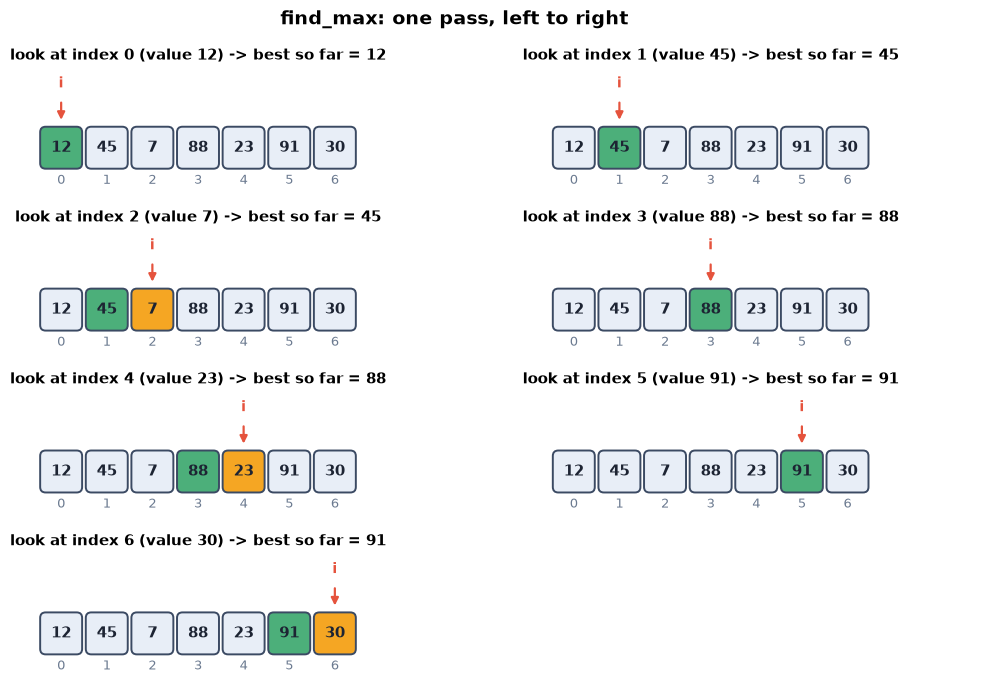

In [3]:
def trace_find_max(values):
    """Build one picture per step of find_max."""
    states = []
    best_i = 0
    for i in range(len(values)):
        if values[i] > values[best_i]:
            best_i = i
        hl = {best_i: "done"}
        if i != best_i:
            hl[i] = "active"
        states.append({
            "values": values,
            "highlight": hl,
            "pointers": {"i": i},
            "caption": f"look at index {i} (value {values[i]}) -> best so far = {values[best_i]}",
        })
    return states

draw_steps(trace_find_max(sales), ncols=2, title="find_max: one pass, left to right")

In [4]:
def sum_all_counted(nums):
    """Sum a list and also count the basic operations we do."""
    ops = 0
    total = 0;  ops += 1                 # 1 assignment
    for x in nums:
        total += x;  ops += 1            # 1 addition per element
    return total, ops


def count_equal_pairs_counted(nums):
    """Count pairs (i < j) with nums[i] == nums[j], counting comparisons."""
    ops = 0
    pairs = 0
    n = len(nums)
    for i in range(n):
        for j in range(i + 1, n):
            ops += 1                     # 1 comparison per pair
            if nums[i] == nums[j]:
                pairs += 1
    return pairs, ops


for n in [10, 100, 1000]:
    data = random_list(n)
    _, ops_sum = sum_all_counted(data)
    _, ops_pairs = count_equal_pairs_counted(data)
    print(f"n = {n:5}:  sum_all does {ops_sum:7,} ops    count_equal_pairs does {ops_pairs:9,} ops")

n =    10:  sum_all does      11 ops    count_equal_pairs does        45 ops
n =   100:  sum_all does     101 ops    count_equal_pairs does     4,950 ops
n =  1000:  sum_all does   1,001 ops    count_equal_pairs does   499,500 ops


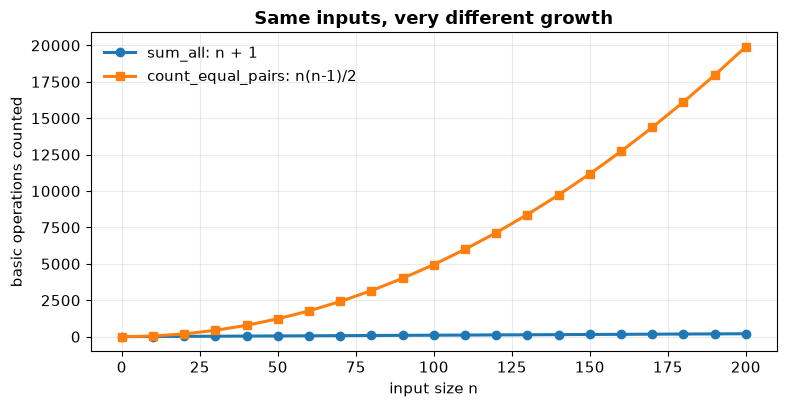

In [5]:
ns = list(range(0, 201, 10))
ops_linear = [sum_all_counted(list(range(n)))[1] for n in ns]
ops_quad = [count_equal_pairs_counted(list(range(n)))[1] for n in ns]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(ns, ops_linear, marker="o", lw=2.2, label="sum_all: n + 1")
ax.plot(ns, ops_quad, marker="s", lw=2.2, label="count_equal_pairs: n(n-1)/2")
ax.set_xlabel("input size n")
ax.set_ylabel("basic operations counted")
ax.set_title("Same inputs, very different growth")
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [6]:
rows = []
for n in [1, 10, 100, 1_000, 10_000, 1_000_000]:
    full = 3 * n**2 + 5 * n + 2
    rows.append({"n": n, "3n² + 5n + 2": full, "3n² part": 3 * n**2,
                 "share from 3n²": f"{3 * n**2 / full:.4%}"})
pd.DataFrame(rows)

,n,3n² + 5n + 2,3n² part,share from 3n²
0,1,10,3,30.0000%
1,10,352,300,85.2273%
2,100,30502,30000,98.3542%
3,1000,3005002,3000000,99.8335%
4,10000,300050002,300000000,99.9833%
5,1000000,3000005000002,3000000000000,99.9998%


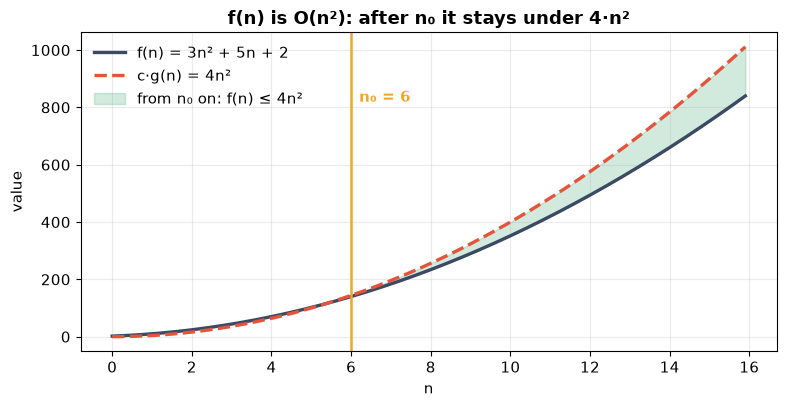

In [7]:
ns = np.arange(0, 16, 0.1)
f = 3 * ns**2 + 5 * ns + 2
upper = 4 * ns**2

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(ns, f, lw=2.4, color=PALETTE["edge"], label="f(n) = 3n² + 5n + 2")
ax.plot(ns, upper, lw=2.4, ls="--", color=PALETTE["special"], label="c·g(n) = 4n²")
ax.axvline(6, color=PALETTE["active"], lw=1.8)
ax.text(6.2, 820, "n₀ = 6", color=PALETTE["active"], fontweight="bold")
ax.fill_between(ns, f, upper, where=ns >= 6, color=PALETTE["done"], alpha=0.25,
                label="from n₀ on: f(n) ≤ 4n²")
ax.set_xlabel("n")
ax.set_ylabel("value")
ax.set_title("f(n) is O(n²): after n₀ it stays under 4·n²")
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

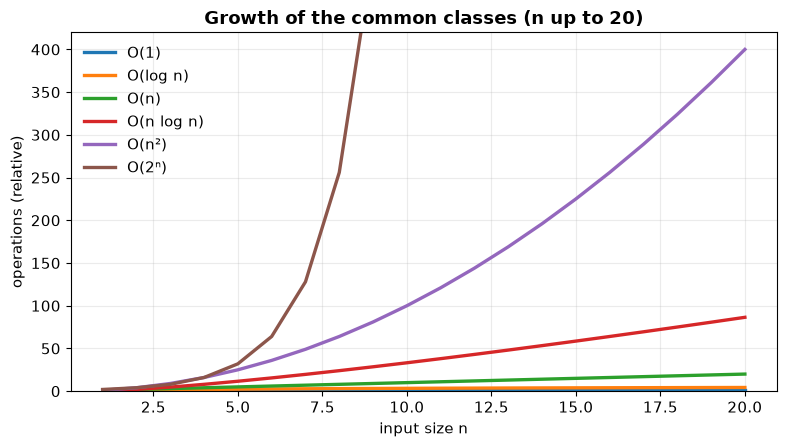

In [8]:
plot_growth(["O(1)", "O(log n)", "O(n)", "O(n log n)", "O(n²)", "O(2ⁿ)"], n_max=20,
            title="Growth of the common classes (n up to 20)")

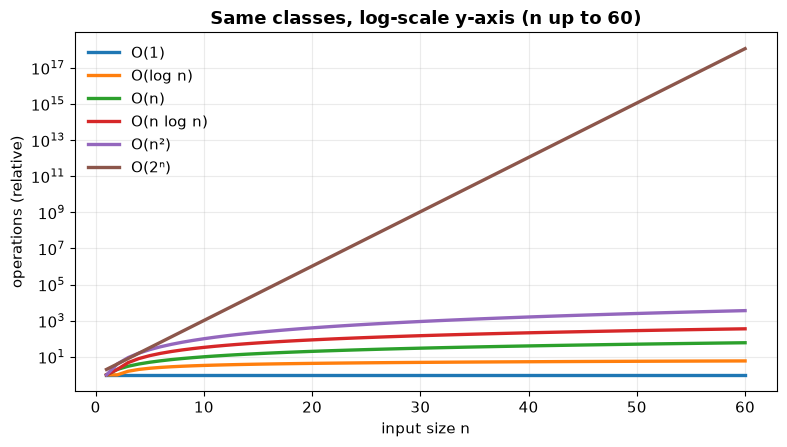

In [9]:
plot_growth(["O(1)", "O(log n)", "O(n)", "O(n log n)", "O(n²)", "O(2ⁿ)"], n_max=60, log_y=True,
            title="Same classes, log-scale y-axis (n up to 60)")

In [10]:
def simple_loop(n):
    """A loop that does one addition per step."""
    total = 0
    for i in range(n):
        total += i
    return total

N = 2_000_000
seconds = time_it(simple_loop, N, repeat=3)
ops_per_second = N / seconds
print(f"About {ops_per_second:,.0f} simple Python steps per second on this machine")

About 14,308,905 simple Python steps per second on this machine


In [11]:
budget = 1e7   # a round, slightly cautious figure for "one second of pure Python"

growth = {
    "O(log n)":   lambda n: math.log2(n),
    "O(n)":       lambda n: n,
    "O(n log n)": lambda n: n * math.log2(n),
    "O(n²)":      lambda n: n ** 2,
    "O(n³)":      lambda n: n ** 3,
    "O(2ⁿ)":      lambda n: 2 ** n,
    "O(n!)":      lambda n: math.factorial(n),
}

def biggest_n(f, budget):
    """Largest n with f(n) <= budget (doubling, then binary search)."""
    hi = 2
    while hi < 10**18 and f(hi) <= budget:
        hi *= 2
    if hi >= 10**18:
        return "practically unlimited"
    lo = hi // 2
    while lo < hi - 1:
        mid = (lo + hi) // 2
        if f(mid) <= budget:
            lo = mid
        else:
            hi = mid
    return f"{lo:,}"

pd.DataFrame([{"class": name, "largest n in ~1 s (10⁷ steps)": biggest_n(f, budget)}
              for name, f in growth.items()])

,class,largest n in ~1 s (10⁷ steps)
0,O(log n),practically unlimited
1,O(n),"10,000,000"
2,O(n log n),"526,172"
3,O(n²),"3,162"
4,O(n³),215
5,O(2ⁿ),23
6,O(n!),10


In [12]:
def get_first(nums):          # O(1): one step, however long the list is
    return nums[0]

def halvings(n):              # O(log n): n is cut in half each time
    steps = 0
    while n > 1:
        n //= 2
        steps += 1
    return steps

def total(nums):              # O(n): touch each element once
    s = 0
    for x in nums:
        s += x
    return s

def sort_it(nums):            # O(n log n): Python's sort (Timsort)
    return sorted(nums)

def all_pairs(nums):          # O(n²): every pair (i, j) with i < j
    return [(nums[i], nums[j]) for i in range(len(nums)) for j in range(i + 1, len(nums))]

def all_subsets(nums):        # O(2ⁿ): every subset (each item is in or out)
    subsets = [[]]
    for x in nums:
        subsets = subsets + [s + [x] for s in subsets]
    return subsets

small = [3, 1, 2, 5]
print("get_first  :", get_first(small))
print("halvings(1_000_000):", halvings(1_000_000), "steps")
print("total      :", total(small))
print("sort_it    :", sort_it(small))
print("all_pairs  :", len(all_pairs(small)), "pairs  (n(n-1)/2 = 6)")
print("all_subsets:", len(all_subsets(small)), "subsets (2^4 = 16)")

get_first  : 3
halvings(1_000_000): 19 steps
total      : 11
sort_it    : [1, 2, 3, 5]
all_pairs  : 6 pairs  (n(n-1)/2 = 6)
all_subsets: 16 subsets (2^4 = 16)


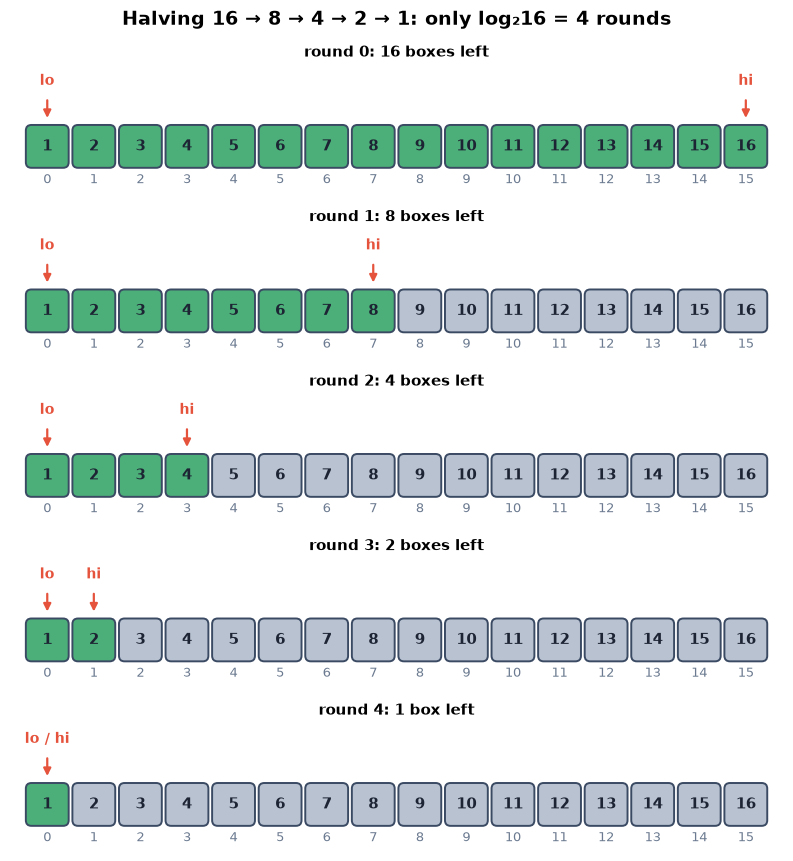

halvings(16) = 4    halvings(1,000,000) = 19


In [13]:
values = list(range(1, 17))
states = []
lo, hi = 0, len(values) - 1
step = 0
while True:
    hl = {i: ("done" if lo <= i <= hi else "muted") for i in range(len(values))}
    states.append({"values": values, "highlight": hl, "pointers": {"lo": lo, "hi": hi},
                   "caption": f"round {step}: {hi - lo + 1} box{'es' if hi > lo else ''} left"})
    if lo == hi:
        break
    hi = (lo + hi) // 2      # keep the left half (as if the target were small)
    step += 1

draw_steps(states, title="Halving 16 → 8 → 4 → 2 → 1: only log₂16 = 4 rounds")
print("halvings(16) =", halvings(16), "   halvings(1,000,000) =", halvings(1_000_000))

In [14]:
def summary_stats(nums):
    """Rule 1 (sequence): O(n) + O(n) + O(n log n) = O(n log n)."""
    lowest = min(nums)              # O(n)
    highest = max(nums)             # O(n)
    middle = sorted(nums)[len(nums) // 2]   # O(n log n)  <- the biggest term wins
    return lowest, highest, middle


def common_customers(list_a, list_b):
    """Rule 4 + hidden loop: for each of a items, `in list_b` scans b items -> O(a · b)."""
    result = []
    for customer in list_a:          # a times
        if customer in list_b:       # hidden loop: up to b comparisons
            result.append(customer)
    return result


def doubling_loop(n):
    """Rule 2 + 3: outer loop n times, inner loop doubles j -> O(n log n)."""
    count = 0
    for i in range(n):        # n times
        j = 1
        while j < n:          # log2(n) times
            j *= 2
            count += 1
    return count

print(summary_stats([5, 3, 9, 1, 7]))
print(common_customers(["Ada", "Bayo", "Chi"], ["Chi", "Dayo", "Ada"]))
print(doubling_loop(16), "inner steps for n = 16  (16 × log2 16 = 64)")

(1, 9, 5)
['Ada', 'Chi']
64 inner steps for n = 16  (16 × log2 16 = 64)


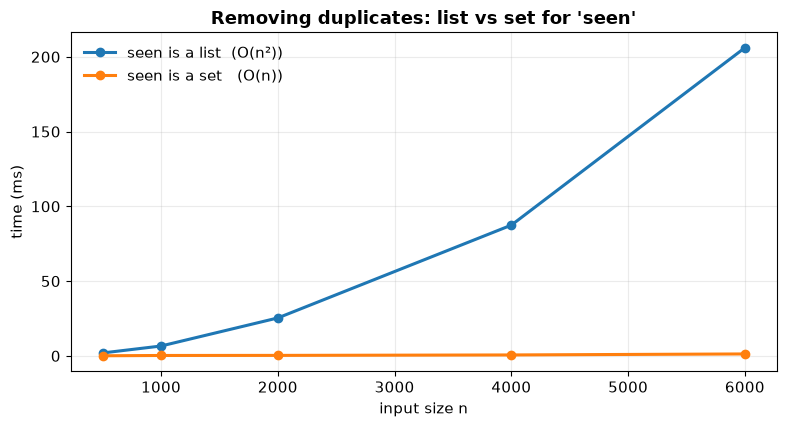

In [15]:
def dedup_with_list(ids):
    """Keep first occurrences. `in seen` is a hidden O(n) scan -> O(n²) total."""
    seen = []
    result = []
    for x in ids:
        if x not in seen:
            seen.append(x)
            result.append(x)
    return result


def dedup_with_set(ids):
    """Same output. `in seen` is O(1) on average for a set -> O(n) total."""
    seen = set()
    result = []
    for x in ids:
        if x not in seen:
            seen.add(x)
            result.append(x)
    return result


ids = random_list(2000)
assert dedup_with_list(ids) == dedup_with_set(ids)   # same answer, check first!

sizes = [500, 1000, 2000, 4000, 6000]
results = benchmark({"seen is a list  (O(n²))": dedup_with_list,
                     "seen is a set   (O(n))": dedup_with_set},
                    make_input=lambda n: random_list(n), sizes=sizes)
plot_benchmark(sizes, results, title="Removing duplicates: list vs set for 'seen'")

In [16]:
def linear_search(nums, target):
    """Return the index of target, or -1. Also return how many comparisons we made."""
    comparisons = 0
    for i, x in enumerate(nums):
        comparisons += 1
        if x == target:
            return i, comparisons
    return -1, comparisons

orders = [31, 7, 58, 12, 90, 44, 3, 67]
print("best case   (target is first):", linear_search(orders, 31))
print("middle      (target is 5th)  :", linear_search(orders, 90))
print("worst case  (target missing) :", linear_search(orders, 100))

best case   (target is first): (0, 1)
middle      (target is 5th)  : (4, 5)
worst case  (target missing) : (-1, 8)


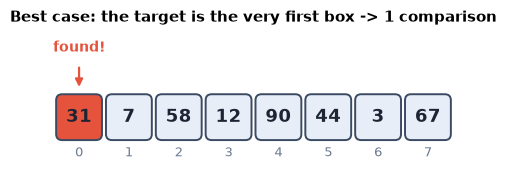

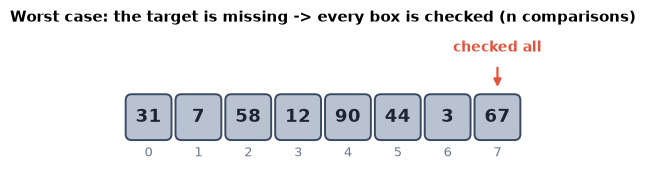

In [17]:
draw_array(orders, highlight={0: "special"}, pointers={"found!": 0},
           title="Best case: the target is the very first box -> 1 comparison")
draw_array(orders, highlight={i: "muted" for i in range(len(orders))}, pointers={"checked all": 7},
           title="Worst case: the target is missing -> every box is checked (n comparisons)")

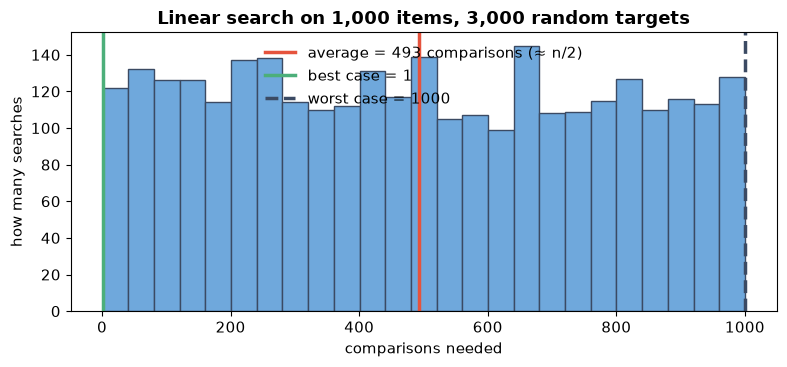

In [18]:
n = 1000
data = list(range(n))
rng = random.Random(7)
counts = [linear_search(data, rng.choice(data))[1] for _ in range(3000)]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(counts, bins=25, color=PALETTE["frontier"], edgecolor=PALETTE["edge"])
ax.axvline(np.mean(counts), color=PALETTE["special"], lw=2.5,
           label=f"average = {np.mean(counts):.0f} comparisons (≈ n/2)")
ax.axvline(1, color=PALETTE["done"], lw=2.5, label="best case = 1")
ax.axvline(n, color=PALETTE["edge"], lw=2.5, ls="--", label=f"worst case = {n}")
ax.set_xlabel("comparisons needed")
ax.set_ylabel("how many searches")
ax.set_title("Linear search on 1,000 items, 3,000 random targets")
ax.legend(frameon=False, loc="upper center")
plt.tight_layout()
plt.show()

In [19]:
def reversed_copy(nums):
    """O(n) time, O(n) extra space: builds a brand new list."""
    out = []
    for i in range(len(nums) - 1, -1, -1):
        out.append(nums[i])
    return out


def reverse_in_place(nums):
    """O(n) time, O(1) extra space: swaps items inside the same list."""
    left, right = 0, len(nums) - 1
    while left < right:
        nums[left], nums[right] = nums[right], nums[left]
        left += 1
        right -= 1
    return nums


def peak_memory_kb(fn, data):
    """Peak extra memory (in KB) used while running fn(data)."""
    tracemalloc.start()
    fn(data)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1024

for n in [10_000, 100_000, 1_000_000]:
    data = list(range(n))
    print(f"n = {n:>9,}:  copy uses {peak_memory_kb(reversed_copy, data):9,.1f} KB extra,"
          f"   in-place uses {peak_memory_kb(reverse_in_place, data):5.1f} KB extra")

n =    10,000:  copy uses      83.1 KB extra,   in-place uses   0.0 KB extra
n =   100,000:  copy uses     782.5 KB extra,   in-place uses   0.0 KB extra
n = 1,000,000:  copy uses   8,252.6 KB extra,   in-place uses   0.1 KB extra


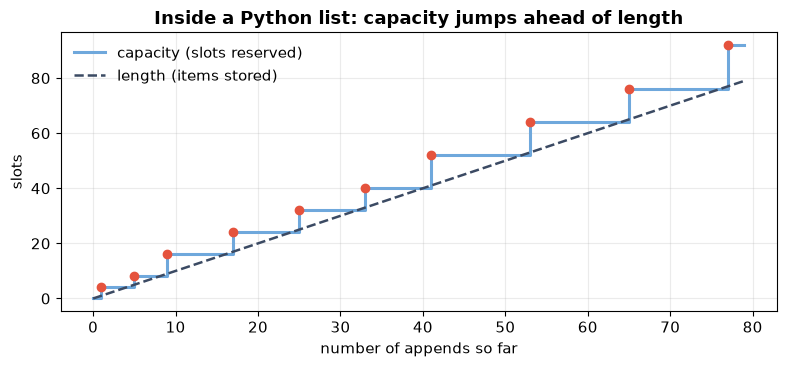

Resizes happened when the length was: [1, 5, 9, 17, 25, 33, 41, 53, 65, 77]


In [20]:
nums = []
sizes_bytes = []
for k in range(80):
    sizes_bytes.append(sys.getsizeof(nums))
    nums.append(k)

empty = sys.getsizeof([])
capacity = [(b - empty) // 8 for b in sizes_bytes]   # 8 bytes per slot on 64-bit Python
resize_points = [k for k in range(1, 80) if capacity[k] != capacity[k - 1]]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.step(range(80), capacity, where="post", lw=2.2, color=PALETTE["frontier"], label="capacity (slots reserved)")
ax.plot(range(80), range(80), lw=1.8, ls="--", color=PALETTE["edge"], label="length (items stored)")
for k in resize_points:
    ax.plot(k, capacity[k], "o", color=PALETTE["special"])
ax.set_xlabel("number of appends so far")
ax.set_ylabel("slots")
ax.set_title("Inside a Python list: capacity jumps ahead of length")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("Resizes happened when the length was:", resize_points)

In [21]:
def total_copy_work(n_appends, growth=2.0):
    """Simulate appends into a growing array; return total items copied during resizes."""
    capacity, length, copies = 1, 0, 0
    for _ in range(n_appends):
        if length == capacity:                       # full: grow and copy everything
            copies += length
            capacity = max(capacity + 1, int(capacity * growth))
        length += 1
    return copies

ns = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
pd.DataFrame([{"appends n": n, "items copied in total": total_copy_work(n),
               "copies per append": round(total_copy_work(n) / n, 3)} for n in ns])

,appends n,items copied in total,copies per append
0,10,15,1.500
1,100,127,1.270
2,1000,1023,1.023
3,10000,16383,1.638
4,100000,131071,1.311
5,1000000,1048575,1.049


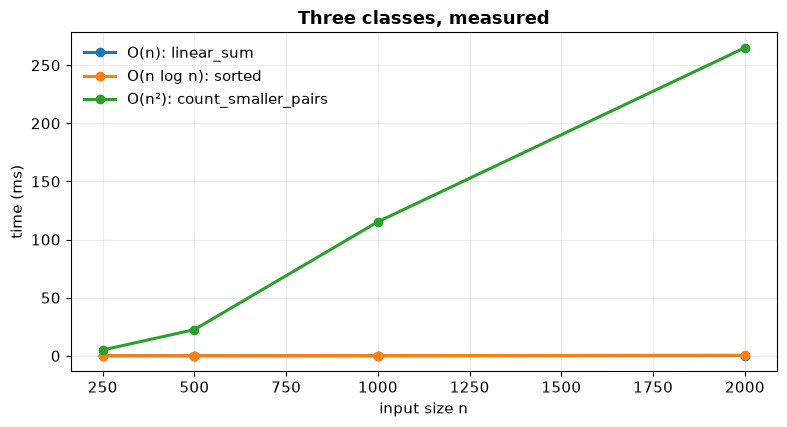

In [22]:
def linear_sum(nums):           # O(n)
    total = 0
    for x in nums:
        total += x
    return total

def sort_copy(nums):            # O(n log n)
    return sorted(nums)

def count_smaller_pairs(nums):  # O(n²)
    count = 0
    for i in range(len(nums)):
        for j in range(i + 1, len(nums)):
            if nums[i] > nums[j]:
                count += 1
    return count

sizes = [250, 500, 1000, 2000]
timings = benchmark({"O(n): linear_sum": linear_sum,
                     "O(n log n): sorted": sort_copy,
                     "O(n²): count_smaller_pairs": count_smaller_pairs},
                    make_input=lambda n: random_list(n), sizes=sizes, repeat=2)
plot_benchmark(sizes, timings, title="Three classes, measured")

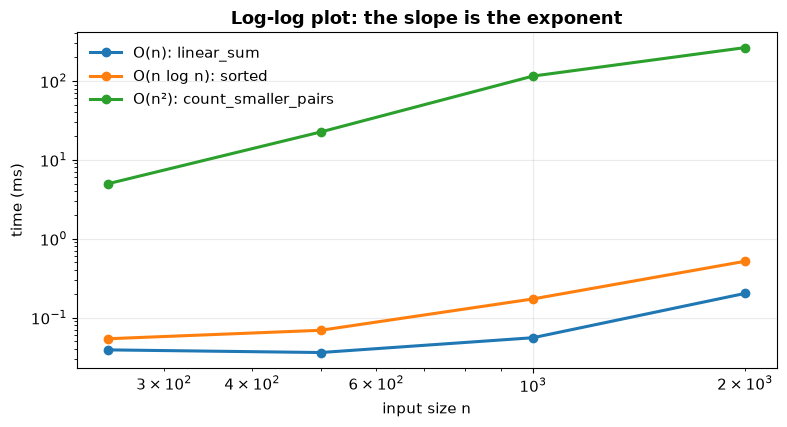

O(n): linear_sum               measured slope ≈ 0.78
O(n log n): sorted             measured slope ≈ 1.11
O(n²): count_smaller_pairs     measured slope ≈ 1.95


In [23]:
plot_benchmark(sizes, timings, log=True, title="Log-log plot: the slope is the exponent")

for label, ts in timings.items():
    slope = np.polyfit(np.log(sizes), np.log(ts), 1)[0]
    print(f"{label:30s} measured slope ≈ {slope:.2f}")

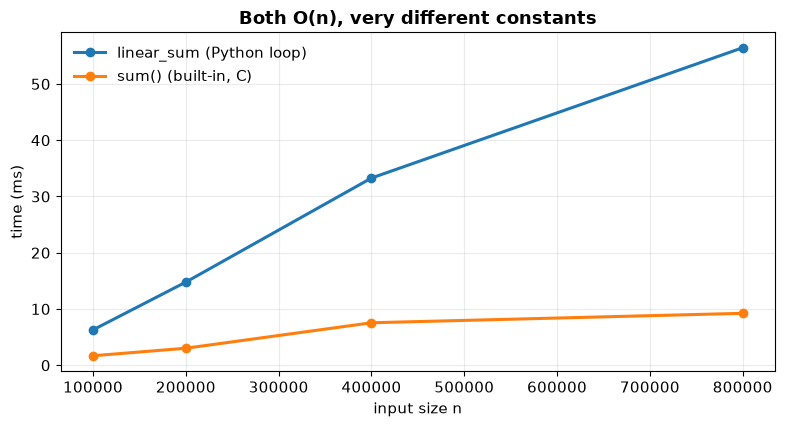

linear_sum (Python loop)       56.44 ms at n = 800,000
sum() (built-in, C)             9.23 ms at n = 800,000
np.sum on a NumPy array         1.49 ms at n = 800,000


In [24]:
sizes = [100_000, 200_000, 400_000, 800_000]
timings = benchmark({"linear_sum (Python loop)": linear_sum,
                     "sum() (built-in, C)": sum},
                    make_input=lambda n: list(range(n)), sizes=sizes, repeat=3)
plot_benchmark(sizes, timings, title="Both O(n), very different constants")
for label, ts in timings.items():
    print(f"{label:28s} {ts[-1] * 1000:7.2f} ms at n = {sizes[-1]:,}")

arr = np.arange(sizes[-1])          # a NumPy array, built once
print(f"{'np.sum on a NumPy array':28s} {time_it(np.sum, arr) * 1000:7.2f} ms at n = {sizes[-1]:,}")

Arrays, Strings & Two Pointers

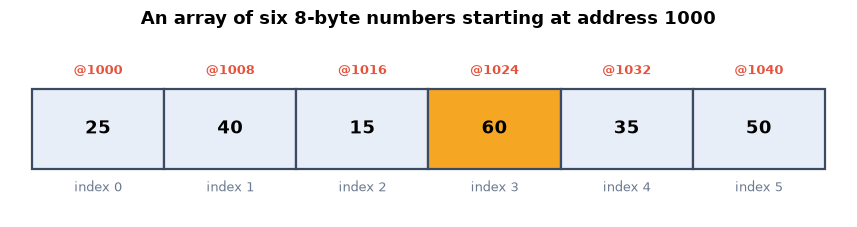

In [25]:
def draw_memory(values, start=1000, slot_size=8, title=None, highlight=None):
    """Draw an array as side-by-side memory slots with their (pretend) addresses."""
    highlight = highlight or {}
    n = len(values)
    fig, ax = plt.subplots(figsize=(1.25 * n + 1.2, 2.4))
    for i, v in enumerate(values):
        colour = PALETTE.get(highlight.get(i, "base"))
        ax.add_patch(plt.Rectangle((i * 1.2, 0), 1.2, 1, fc=colour, ec=PALETTE["edge"], lw=1.6))
        ax.text(i * 1.2 + 0.6, 0.5, str(v), ha="center", va="center", fontsize=13, fontweight="bold")
        ax.text(i * 1.2 + 0.6, -0.28, f"index {i}", ha="center", fontsize=9, color="#6b7a90")
        ax.text(i * 1.2 + 0.6, 1.18, f"@{start + i * slot_size}", ha="center", fontsize=9,
                color=PALETTE["special"], fontweight="bold")
    ax.set_xlim(-0.2, n * 1.2 + 0.2)
    ax.set_ylim(-0.6, 1.7)
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

draw_memory([25, 40, 15, 60, 35, 50], highlight={3: "active"},
            title="An array of six 8-byte numbers starting at address 1000")

In [26]:
prices = np.array([25, 40, 15, 60, 35, 50], dtype=np.int64)
base = prices.ctypes.data                      # real address of element 0
offsets = [prices[i:].ctypes.data - base for i in range(len(prices))]

print("bytes per item :", prices.itemsize)
print("offset of each element from element 0:", offsets)

bytes per item : 8
offset of each element from element 0: [0, 8, 16, 24, 32, 40]


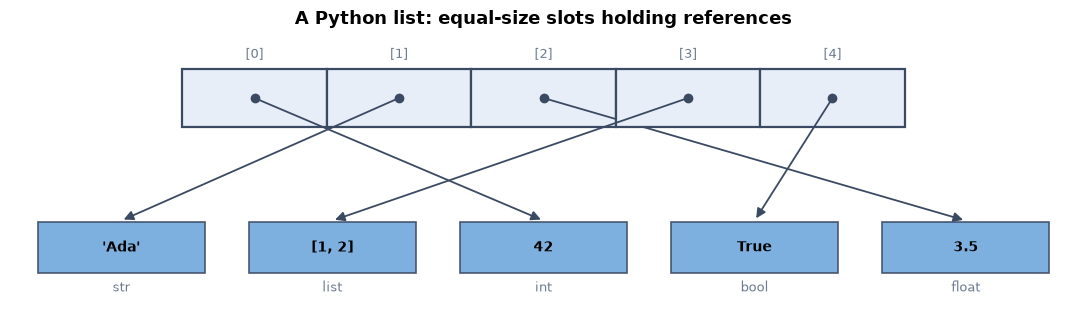

In [27]:
from matplotlib.patches import FancyArrowPatch

def draw_references(items, title="A Python list: equal-size slots holding references"):
    """Top row: the list's slots. Bottom row: the objects they point to, scattered in memory."""
    n = len(items)
    fig, ax = plt.subplots(figsize=(1.9 * n + 1.5, 3.4))
    order = [2, 0, 4, 1, 3, 5, 6, 7][:n]          # where each object happens to live (scattered)
    row_left = (n * 1.3 - (n - 1) * 1.9) / 2       # centre the object row under the slots
    for i, obj in enumerate(items):
        ax.add_patch(plt.Rectangle((i * 1.3, 2), 1.3, 0.8, fc=PALETTE["base"], ec=PALETTE["edge"], lw=1.6))
        ax.plot(i * 1.3 + 0.65, 2.4, "o", color=PALETTE["edge"])
        ox = row_left + order[i] * 1.9
        label = repr(obj)
        ax.add_patch(plt.Rectangle((ox - 0.75, 0), 1.5, 0.7, fc=PALETTE["frontier"], ec=PALETTE["edge"],
                                   lw=1.2, alpha=0.9))
        ax.text(ox, 0.35, label, ha="center", va="center", fontsize=10, fontweight="bold")
        ax.text(ox, -0.25, type(obj).__name__, ha="center", fontsize=9, color="#6b7a90")
        ax.add_patch(FancyArrowPatch((i * 1.3 + 0.65, 2.4), (ox, 0.72), arrowstyle="-|>",
                                     mutation_scale=14, color=PALETTE["edge"], lw=1.3))
        ax.text(i * 1.3 + 0.65, 2.95, f"[{i}]", ha="center", fontsize=9, color="#6b7a90")
    ax.set_xlim(min(-0.3, row_left - 1.0), max(n * 1.3 + 0.3, row_left + (n - 1) * 1.9 + 1.0))
    ax.set_ylim(-0.6, 3.3)
    ax.axis("off")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

draw_references([42, "Ada", 3.5, [1, 2], True])

In [3]:
n = 1_000_000
as_list = list(range(n))
as_array = np.arange(n, dtype=np.int64)

list_bytes = sys.getsizeof(as_list) + sum(sys.getsizeof(x) for x in as_list)
print(f"list of 1M ints : {list_bytes / 1e6:6.1f} MB  (slots + one int object per number)")
print(f"NumPy int64 array: {as_array.nbytes / 1e6:6.1f} MB  (just the raw 8-byte numbers)")

list of 1M ints :   36.0 MB  (slots + one int object per number)
NumPy int64 array:    8.0 MB  (just the raw 8-byte numbers)


In [5]:
class DynamicArray:
    """A list-like array that grows by doubling, built on a fixed-size block."""

    def __init__(self):
        self._capacity = 1
        self._length = 0
        self._block = [None] * self._capacity   # stands in for a fixed block of memory
        self.copies = 0                         # how many item copies resizing has cost

    def __len__(self):
        return self._length

    def _check_index(self, index):
        if not 0 <= index < self._length:
            raise IndexError(f"index {index} out of range for length {self._length}")

    def __getitem__(self, index):               # O(1): straight to the slot
        self._check_index(index)
        return self._block[index]

    def __setitem__(self, index, value):        # O(1)
        self._check_index(index)
        self._block[index] = value

    def _resize(self, new_capacity):            # O(n): copy every item to a new block
        new_block = [None] * new_capacity
        for i in range(self._length):
            new_block[i] = self._block[i]
            self.copies += 1
        self._block = new_block
        self._capacity = new_capacity

    def append(self, value):                    # amortised O(1)
        if self._length == self._capacity:
            self._resize(2 * self._capacity)
        self._block[self._length] = value
        self._length += 1

    def insert(self, index, value):             # O(n): shift everything after index right
        if not 0 <= index <= self._length:
            raise IndexError(f"insert index {index} out of range")
        if self._length == self._capacity:
            self._resize(2 * self._capacity)
        for i in range(self._length, index, -1):
            self._block[i] = self._block[i - 1]
        self._block[index] = value
        self._length += 1

    def pop(self):                              # O(1): remove from the end
        if self._length == 0:
            raise IndexError("pop from empty array")
        self._length -= 1
        value = self._block[self._length]
        self._block[self._length] = None
        return value

    def remove_at(self, index):                 # O(n): shift everything after index left
        self._check_index(index)
        value = self._block[index]
        for i in range(index, self._length - 1):
            self._block[i] = self._block[i + 1]
        self._block[self._length - 1] = None
        self._length -= 1
        return value

    def slots(self):
        """All reserved slots, with '·' for empty ones (for drawing)."""
        return [self._block[i] if i < self._length else "·" for i in range(self._capacity)]

    def __repr__(self):
        items = [self._block[i] for i in range(self._length)]
        return f"DynamicArray({items}, length={self._length}, capacity={self._capacity})"

arr = DynamicArray()
for city in ["Lagos", "Abuja", "Kano"]:
    arr.append(city)
print(arr)
print("arr[1] =", arr[1])
arr.insert(0, "Ibadan")
print("after insert(0, 'Ibadan'):", arr)
print("pop() ->", arr.pop(), "|", arr)
print("remove_at(1) ->", arr.remove_at(1), "|", arr)

DynamicArray(['Lagos', 'Abuja', 'Kano'], length=3, capacity=4)
arr[1] = Abuja
after insert(0, 'Ibadan'): DynamicArray(['Ibadan', 'Lagos', 'Abuja', 'Kano'], length=4, capacity=4)
pop() -> Kano | DynamicArray(['Ibadan', 'Lagos', 'Abuja'], length=3, capacity=4)
remove_at(1) -> Lagos | DynamicArray(['Ibadan', 'Abuja'], length=2, capacity=4)


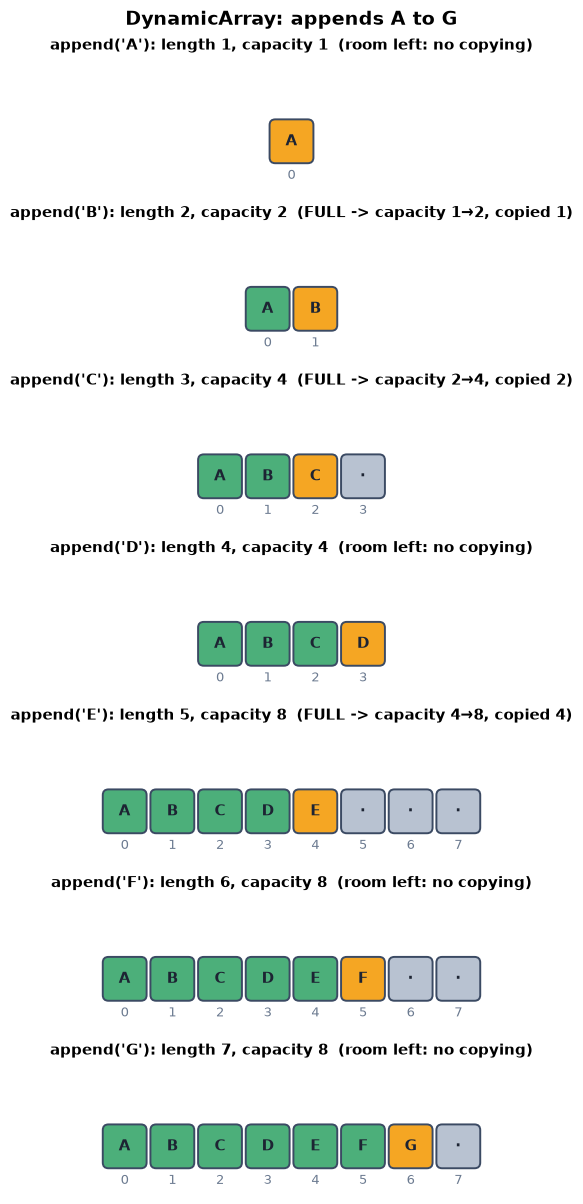

total copies for 7 appends: 7


In [6]:
arr = DynamicArray()
states = []
for k, letter in enumerate("ABCDEFG"):
    cap_before, copies_before = arr._capacity, arr.copies
    arr.append(letter)
    slots = arr.slots()
    hl = {i: ("done" if slots[i] != "·" else "muted") for i in range(len(slots))}
    hl[len(arr) - 1] = "active"
    note = (f"FULL -> capacity {cap_before}→{arr._capacity}, copied {arr.copies - copies_before}"
            if arr._capacity != cap_before else "room left: no copying")
    states.append({"values": slots, "highlight": hl,
                   "caption": f"append('{letter}'): length {len(arr)}, capacity {arr._capacity}  ({note})"})
draw_steps(states, title="DynamicArray: appends A to G")
print("total copies for 7 appends:", arr.copies)

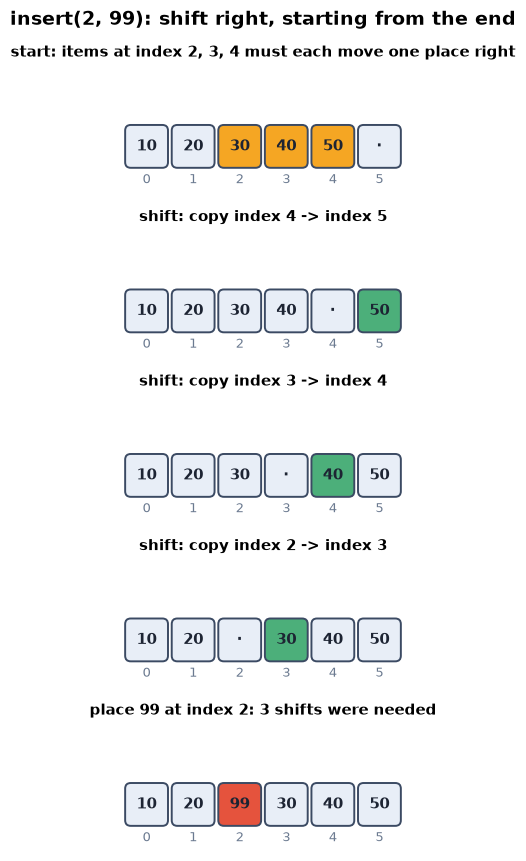

In [7]:
values = [10, 20, 30, 40, 50, "·"]   # one spare slot at the end
index, new_value = 2, 99
states = [{"values": list(values), "highlight": {2: "active", 3: "active", 4: "active"},
           "caption": "start: items at index 2, 3, 4 must each move one place right"}]
for i in range(5, index, -1):
    values[i] = values[i - 1]
    values[i - 1] = "·"
    states.append({"values": list(values), "highlight": {i: "done"},
                   "caption": f"shift: copy index {i - 1} -> index {i}"})
values[index] = new_value
states.append({"values": list(values), "highlight": {index: "special"},
               "caption": f"place {new_value} at index {index}: 3 shifts were needed"})
draw_steps(states, ncols=1, title="insert(2, 99): shift right, starting from the end")

In [ ]:
def build_with_append(n):
    items = []
    for i in range(n):
        items.append(i)          # O(1) amortised
    return items

def build_with_insert_front(n):
    items = []
    for i in range(n):
        items.insert(0, i)       # O(n) each: shifts everything
    return items

def build_with_deque_appendleft(n):
    items = deque()
    for i in range(n):
        items.appendleft(i)      # O(1): deque is built for both ends
    return items

sizes = [10_000, 20_000, 40_000, 80_000]
results = benchmark({"list.insert(0, x)  O(n²) total": build_with_insert_front,
                     "list.append(x)  O(n) total": build_with_append,
                     "deque.appendleft(x)  O(n) total": build_with_deque_appendleft},
                    make_input=lambda n: n, sizes=sizes, repeat=2)
plot_benchmark(sizes, results, title="Adding n items: front of a list vs. back vs. deque")

NameError: name 'deque' is not defined

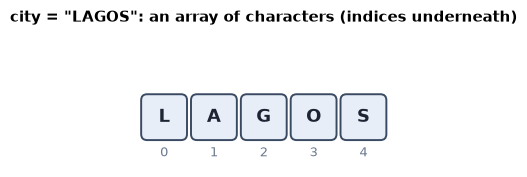

In [12]:
city = "LAGOS"
draw_array(list(city), title='city = "LAGOS": an array of characters (indices underneath)')

In [13]:
city = "LAGOS"
try:
    city[0] = "J"                  # try to change one character
except TypeError as error:
    print("TypeError:", error)

new_city = "J" + city[1:]          # build a NEW string instead
print(city, "->", new_city)
print("same object?", city is new_city)

TypeError: 'str' object does not support item assignment
LAGOS -> JAGOS
same object? False


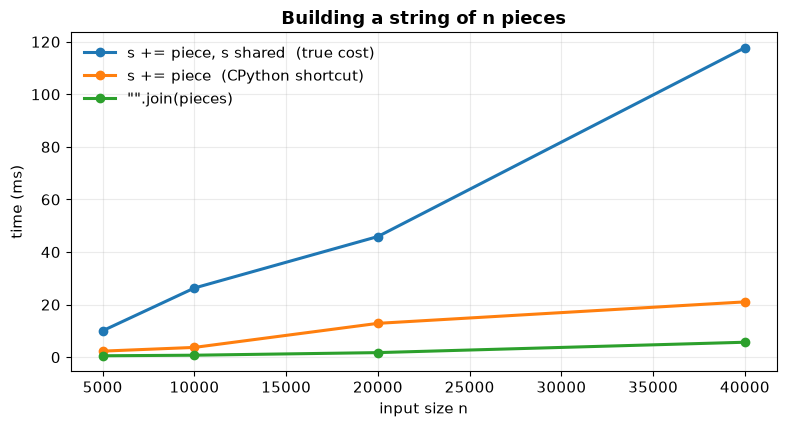

In [14]:
def build_with_join(n):
    pieces = []
    for i in range(n):
        pieces.append("TX")
    return "".join(pieces)                 # O(n) total

def build_with_plus(n):
    s = ""
    for i in range(n):
        s += "TX"                          # may be optimised by CPython (not guaranteed)
    return s

def build_with_plus_shared(n):
    s = ""
    for i in range(n):
        previous = s                       # a second reference to s (like keeping a log)
        s += "TX"                          # now Python MUST copy: O(n²) total
    return s

assert build_with_join(100) == build_with_plus(100) == build_with_plus_shared(100)
sizes = [5_000, 10_000, 20_000, 40_000]
results = benchmark({"s += piece, s shared  (true cost)": build_with_plus_shared,
                     "s += piece  (CPython shortcut)": build_with_plus,
                     '"".join(pieces)': build_with_join},
                    make_input=lambda n: n, sizes=sizes, repeat=2)
plot_benchmark(sizes, results, title="Building a string of n pieces")

In [15]:
nums = [10, 20, 30, 40, 50]
part = nums[1:4]
part[0] = 999
print("slice  :", part)
print("original is unchanged:", nums)

slice  : [999, 30, 40]
original is unchanged: [10, 20, 30, 40, 50]


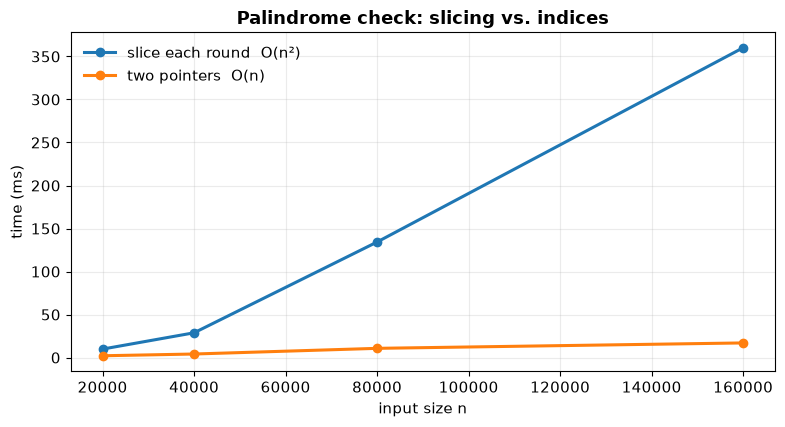

In [16]:
def is_palindrome_slicing(s):
    """Each round copies s[1:-1]: O(n) per round, n/2 rounds -> O(n²) time."""
    while len(s) > 1:
        if s[0] != s[-1]:
            return False
        s = s[1:-1]               # copy!
    return True

def is_palindrome_pointers(s):
    """Two indices walk inwards: O(n) time, O(1) extra space."""
    left, right = 0, len(s) - 1
    while left < right:
        if s[left] != s[right]:
            return False
        left += 1
        right -= 1
    return True

def make_palindrome(n):
    half = "".join(random.Random(n).choice("abc") for _ in range(n // 2))
    return half + half[::-1]

assert is_palindrome_slicing(make_palindrome(100)) and is_palindrome_pointers(make_palindrome(100))
sizes = [20_000, 40_000, 80_000, 160_000]
results = benchmark({"slice each round  O(n²)": is_palindrome_slicing,
                     "two pointers  O(n)": is_palindrome_pointers},
                    make_input=make_palindrome, sizes=sizes, repeat=2)
plot_benchmark(sizes, results, title="Palindrome check: slicing vs. indices")

In [17]:
readings = np.array([10, 20, 30, 40, 50])
window = readings[1:4]          # a VIEW, no copy
window[0] = 999
print("view    :", window)
print("original:", readings, "  <- changed too!")

safe = readings[1:4].copy()     # an explicit copy when you need independence
safe[0] = -1
print("after editing the copy, original:", readings)

view    : [999  30  40]
original: [ 10 999  30  40  50]   <- changed too!
after editing the copy, original: [ 10 999  30  40  50]


In [18]:
def pair_sum_brute(nums, target):
    """Check every pair. Time O(n²), space O(1)."""
    for i in range(len(nums)):
        for j in range(i + 1, len(nums)):
            if nums[i] + nums[j] == target:
                return (i, j)
    return None


def pair_sum_two_pointers(nums, target):
    """nums must be sorted. Time O(n), space O(1)."""
    left, right = 0, len(nums) - 1
    while left < right:
        total = nums[left] + nums[right]
        if total == target:
            return (left, right)
        if total < target:
            left += 1             # need a bigger sum
        else:
            right -= 1            # need a smaller sum
    return None

bundles = [1, 3, 4, 6, 8, 11, 15]
print(pair_sum_brute(bundles, 10), pair_sum_two_pointers(bundles, 10))

(2, 3) (2, 3)


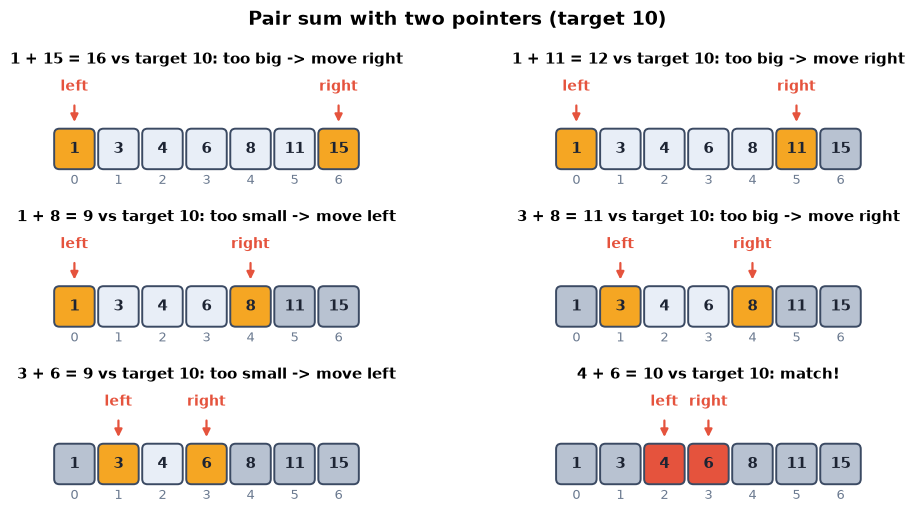

In [19]:
def trace_pair_sum(nums, target):
    left, right = 0, len(nums) - 1
    states = []
    while left < right:
        total = nums[left] + nums[right]
        hl = {i: "muted" for i in range(len(nums)) if i < left or i > right}
        if total == target:
            hl.update({left: "special", right: "special"})
            verdict = "match!"
        else:
            hl.update({left: "active", right: "active"})
            verdict = "too small -> move left" if total < target else "too big -> move right"
        states.append({"values": nums, "highlight": hl, "pointers": {"left": left, "right": right},
                       "caption": f"{nums[left]} + {nums[right]} = {total} vs target {target}: {verdict}"})
        if total == target:
            break
        if total < target:
            left += 1
        else:
            right -= 1
    return states

draw_steps(trace_pair_sum(bundles, 10), ncols=2, title="Pair sum with two pointers (target 10)")

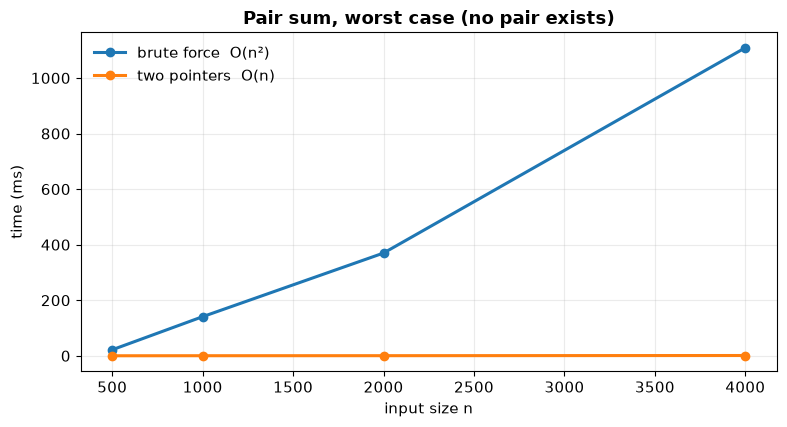

In [20]:
def make_sorted(n):
    return sorted(random_list(n, seed=n))

sizes = [500, 1000, 2000, 4000]
results = benchmark({"brute force  O(n²)": lambda xs: pair_sum_brute(xs, -1),
                     "two pointers  O(n)": lambda xs: pair_sum_two_pointers(xs, -1)},
                    make_input=make_sorted, sizes=sizes, repeat=2)
plot_benchmark(sizes, results, title="Pair sum, worst case (no pair exists)")

In [21]:
def dedupe_sorted(nums):
    """Remove repeats from a sorted list in place. Time O(n), extra space O(1)."""
    if not nums:
        return nums
    write = 1                                # nums[0] is always kept
    for read in range(1, len(nums)):
        if nums[read] != nums[write - 1]:    # a value we haven't kept yet
            nums[write] = nums[read]
            write += 1
    del nums[write:]                         # trim the leftovers
    return nums

print(dedupe_sorted([1, 1, 2, 2, 2, 3, 4, 4]))

[1, 2, 3, 4]


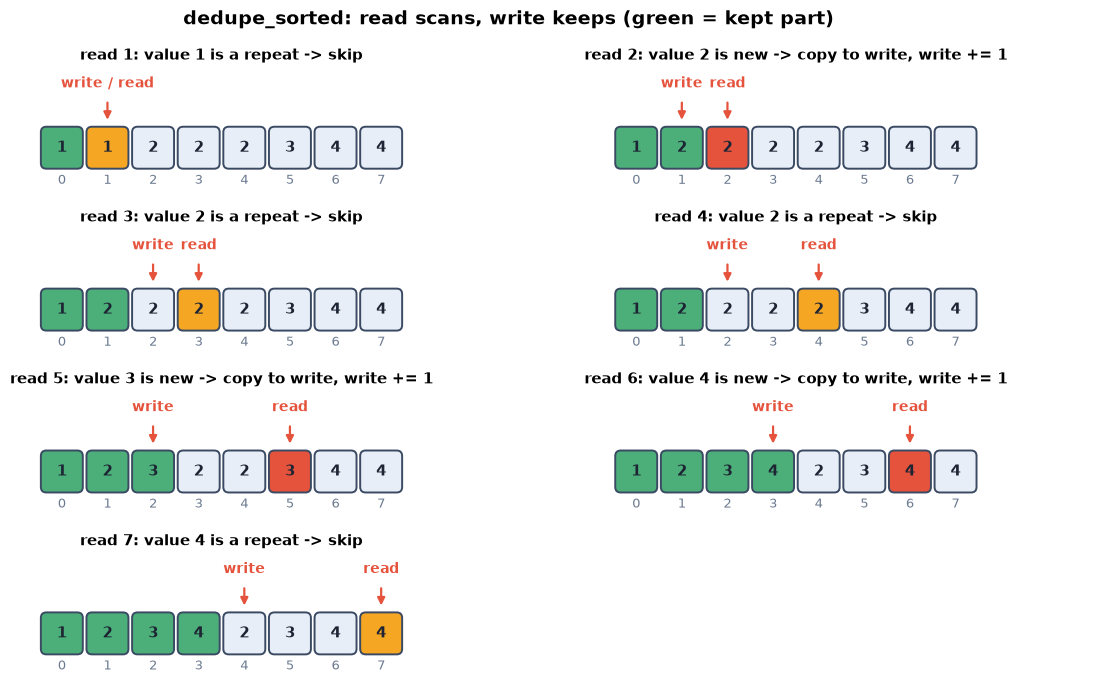

unique part: [1, 2, 3, 4]


In [22]:
values = [1, 1, 2, 2, 2, 3, 4, 4]
write = 1
states = []
for read in range(1, len(values)):
    is_new = values[read] != values[write - 1]
    if is_new:
        values[write] = values[read]
    hl = {i: "done" for i in range(write + (1 if is_new else 0))}
    hl[read] = "special" if is_new else "active"
    states.append({"values": list(values), "highlight": hl, "pointers": {"write": write, "read": read},
                   "caption": f"read {read}: value {values[read]} " +
                              ("is new -> copy to write, write += 1" if is_new else "is a repeat -> skip")})
    if is_new:
        write += 1
draw_steps(states, ncols=2, title="dedupe_sorted: read scans, write keeps (green = kept part)")
print("unique part:", values[:write])

In [23]:
revenue = [12, 30, 18, 5, 40, 22, 8, 35, 45, 10, 28, 16, 50, 9]

def best_window_brute(nums, k):
    """Sum every window from scratch. Time O(n·k)."""
    best = None
    for start in range(len(nums) - k + 1):
        total = sum(nums[start:start + k])         # k additions (and a slice copy)
        if best is None or total > best:
            best = total
    return best

def best_window_sliding(nums, k):
    """Add the newcomer, subtract the leaver. Time O(n), space O(1)."""
    if k <= 0 or k > len(nums):
        return None
    total = sum(nums[:k])                          # first window
    best = total
    for right in range(k, len(nums)):
        total += nums[right] - nums[right - k]     # slide by one day
        best = max(best, total)
    return best

print(best_window_brute(revenue, 4), best_window_sliding(revenue, 4))

118 118


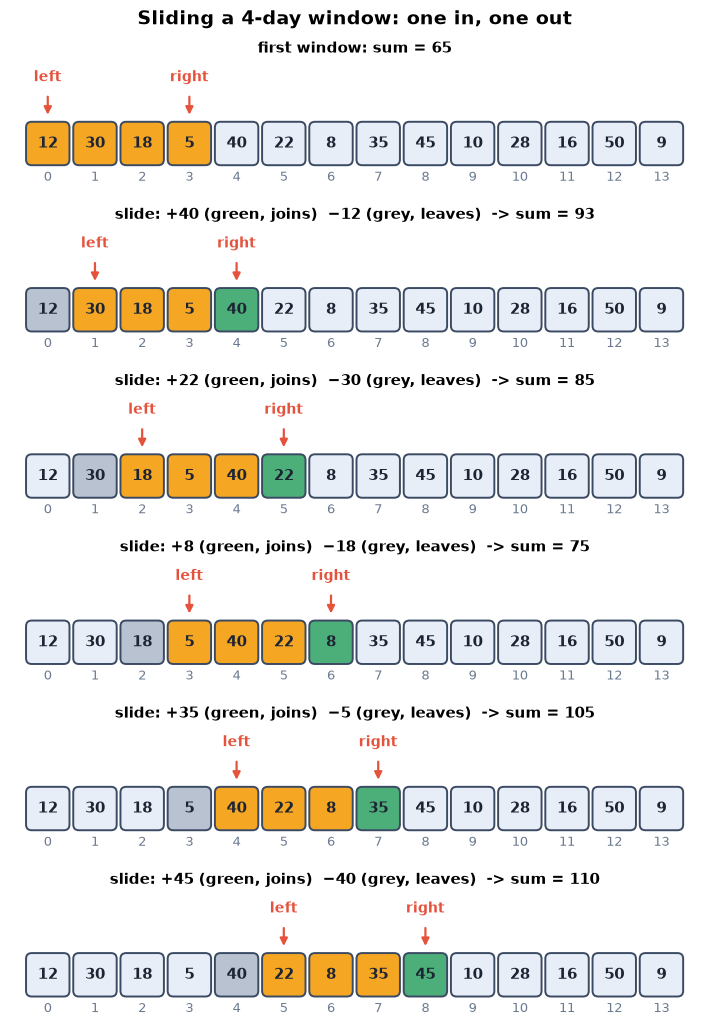

In [24]:
k = 4
states = []
total = sum(revenue[:k])
states.append({"values": revenue, "highlight": {i: "active" for i in range(k)},
               "pointers": {"left": 0, "right": k - 1}, "caption": f"first window: sum = {total}"})
for right in range(k, 9):
    left = right - k + 1
    total += revenue[right] - revenue[right - k]
    hl = {i: "active" for i in range(left, right + 1)}
    hl[right - k] = "muted"
    hl[right] = "done"
    states.append({"values": revenue, "highlight": hl, "pointers": {"left": left, "right": right},
                   "caption": f"slide: +{revenue[right]} (green, joins)  −{revenue[right - k]} (grey, leaves)  -> sum = {total}"})
draw_steps(states, title="Sliding a 4-day window: one in, one out")

In [25]:
frames = []
k = 4
total = sum(revenue[:k])
best, best_left = total, 0
for left in range(0, len(revenue) - k + 1):
    if left > 0:
        total += revenue[left + k - 1] - revenue[left - 1]
    if total > best:
        best, best_left = total, left
    hl = {i: "special" for i in range(best_left, best_left + k)}
    hl.update({i: "active" for i in range(left, left + k)})
    frames.append({"values": revenue, "highlight": hl,
                   "caption": f"days {left}-{left + k - 1}: total {total}   best so far {best} (days {best_left}-{best_left + k - 1})"})
animate_bars(frames, title="Best 4-day revenue: sliding window", interval=700)

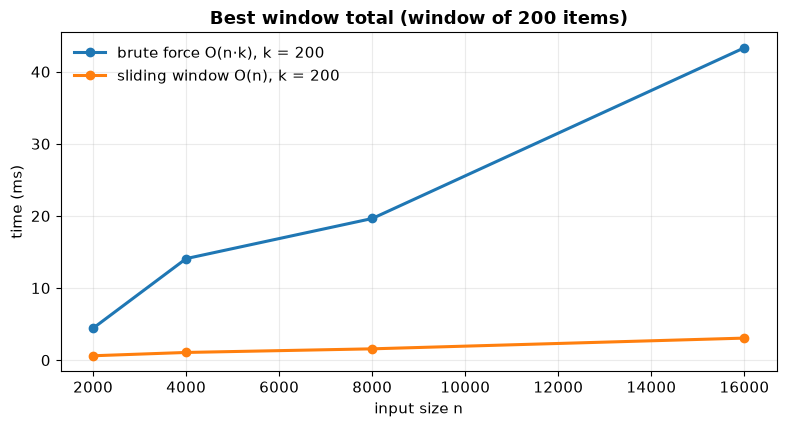

In [26]:
sizes = [2_000, 4_000, 8_000, 16_000]
k = 200
results = benchmark({f"brute force O(n·k), k = {k}": lambda xs: best_window_brute(xs, k),
                     f"sliding window O(n), k = {k}": lambda xs: best_window_sliding(xs, k)},
                    make_input=lambda n: random_list(n), sizes=sizes, repeat=2)
plot_benchmark(sizes, results, title="Best window total (window of 200 items)")

In [27]:
def longest_unique(s):
    """Length of the longest substring without repeated characters. Time O(n), space O(alphabet)."""
    last_seen = {}
    left = 0
    best = 0
    for right, ch in enumerate(s):
        if ch in last_seen and last_seen[ch] >= left:   # ch is inside the current window
            left = last_seen[ch] + 1                    # jump past its previous copy
        last_seen[ch] = right
        best = max(best, right - left + 1)
    return best

for text in ["abcabcbb", "bbbbb", "pwwkew", ""]:
    print(f"{text!r:12} -> {longest_unique(text)}")

'abcabcbb'   -> 3
'bbbbb'      -> 1
'pwwkew'     -> 3
''           -> 0
